# Track 03: diagnose beta, then test one longer window

Place this notebook in your sprint repository's `research/` folder and run it
with the same environment as the corrected IC notebook. It is standalone apart
from your merged Part 1 `leader_flow_impulse`; no new companion module is needed.

**Purpose:** decide whether the beta adjustment looks unstable or merely does not
improve predictions. The first stage examines inputs and rankings only. It cannot
establish predictive value or an objective verdict that beta is "wrong".

**Stage A (default):** describe 168-hour betas, hourly changes, extremes, low leader
variance, and how beta alters the reversal ranking. Select examples using feature
changes, never realized profits. Export the diagnostics without testing a new signal.

**Stage B (optional):** compare 336-hour beta with 168-hour beta and plain reversal,
keeping all other signal settings fixed. Enable only after inspecting Stage A and
recording the follow-up plan in your PR. The toggle controls a new exploratory
performance experiment; this notebook never picks a winning window automatically.

Your original/corrected results remain part of the record. This is not untouched
validation. Do not download, inspect or tune on the sprint holdout or forward data.
The diagnostics are not a trading audit and no fees or trading weights are modeled.

**Verification:** 16 synthetic correctness tests passed. Every code cell completed
with the optional comparison enabled, and the default diagnostic-only skip/save
path was also exercised. Charts were visually checked. Outputs are cleared.
Real training-panel results and the pinned repository environment were not run here.


In [1]:
import sys
from pathlib import Path
ROOT=next((p for p in (Path.cwd(),*Path.cwd().parents)
           if (p/'src'/'contrib'/'janice.py').is_file()),None)
if ROOT is None:
    raise FileNotFoundError('Run this notebook inside your sprint clone with src/contrib/janice.py.')
sys.path.insert(0,str(ROOT))
from src.contrib.janice import leader_flow_impulse
import matplotlib.pyplot as plt
from IPython.display import display
print('Repository:',ROOT)


Repository: /Users/janicejizhe/Desktop/quant sprint/open-quant-sprint


## 1. Functions
The causal feature definitions, strict warm-up, common-sample IC and joint block
bootstrap below match the corrected notebook. The new functions add diagnostics
and a common-sample window comparison. Future labels remain research targets only.


In [2]:
from dataclasses import asdict, dataclass, replace
import hashlib
import json
import math
from pathlib import Path
import platform
import unittest

import numpy as np
import pandas as pd
from pandas.testing import assert_frame_equal, assert_series_equal

LEADERS = ('BTCUSDT', 'ETHUSDT')
HOUR_NS = 3_600_000_000_000


@dataclass(frozen=True)
class Params:
    gap_window: int = 4
    beta_window: int = 168
    impulse_span: int = 4
    strong_quantile: float = 0.9
    quantile_window: int = 720
    horizons: tuple = (1, 2, 4, 8, 24)
    lags: tuple = (0, 1)


@dataclass(frozen=True)
class Inference:
    bootstrap_reps: int = 1000
    block_hours: int = 168
    sensitivity_blocks: tuple = (24, 72, 168)
    sensitivity_hac: tuple = (24, 72, 168)
    min_group: int = 30
    seed: int = 20261116


def validate_panel(df):
    required = ['timestamp', 'symbol', 'close', 'quote_volume', 'taker_buy_quote_volume']
    if not set(required) <= set(df):
        raise ValueError('Missing columns: ' + str(sorted(set(required) - set(df))))
    d = df.copy()
    d['timestamp'] = pd.to_datetime(d['timestamp'], utc=True)
    if d.empty or d[['timestamp', 'symbol']].isna().any().any():
        raise ValueError('Empty panel or missing timestamp/symbol')
    if d.duplicated(['timestamp', 'symbol']).any():
        raise ValueError('Duplicate timestamp/symbol keys')
    names = set(d['symbol'])
    if len(names) != 20 or not set(LEADERS) <= names:
        raise ValueError('Expected BTC, ETH and exactly 18 alts')
    d = d.sort_values(['timestamp', 'symbol']).reset_index(drop=True)
    hours = pd.DatetimeIndex(d['timestamp'].unique())
    if not hours.equals(pd.date_range(hours[0], hours[-1], freq='h')):
        raise ValueError('Panel has missing hours; do not silently fill or compress time')
    if not (hours == hours.floor('h')).all() or not d.groupby('timestamp').size().eq(20).all():
        raise ValueError('Expected complete 20-symbol cross-sections on UTC hours')
    for col in required[2:]:
        d[col] = d[col].astype(float)
    if not np.isfinite(d[required[2:]].to_numpy()).all() or not d['close'].gt(0).all():
        raise ValueError('Non-finite data or nonpositive close')
    if not (d['quote_volume'].ge(0) & d['taker_buy_quote_volume'].ge(0)
            & d['taker_buy_quote_volume'].le(d['quote_volume'])).all():
        raise ValueError('Invalid volume bounds')
    return d


def wide(df, col):
    return df.pivot(index='timestamp', columns='symbol', values=col).sort_index()


def hourly_log_returns(df):
    return np.log(wide(df, 'close')).diff()


def rolling_beta(alt_rets, lead, window, min_periods=None):
    # Full windows by default. The optional shorter minimum is ONLY for the
    # explicitly labelled warm-up sensitivity check, not an automatic fallback.
    m = window if min_periods is None else min_periods
    cov = alt_rets.rolling(window, min_periods=m).cov(lead).shift(1)
    var = lead.rolling(window, min_periods=m).var().shift(1)
    return cov.div(var.where(var > 1e-12), axis=0)


def build_features(df, p, full_history=True):
    d = validate_panel(df)
    ret = hourly_log_returns(d)
    q = wide(d, 'quote_volume')[list(LEADERS)]
    lead = (ret[list(LEADERS)] * q).sum(axis=1, min_count=2).div(
        q.sum(axis=1).where(lambda v: v > 0))
    alts = ret.columns.difference(LEADERS)
    beta = rolling_beta(ret[alts], lead, p.beta_window,
                        None if full_history else p.beta_window // 2)
    alt_recent = ret[alts].rolling(p.gap_window).sum()
    lead_recent = lead.rolling(p.gap_window).sum()
    signal = -(alt_recent - beta.mul(lead_recent, axis=0))
    imp_rows = leader_flow_impulse(d, span=p.impulse_span)
    impulse = imp_rows.groupby(d['timestamp'], sort=True).first().reindex(ret.index)
    size = impulse.abs()
    minimum = p.quantile_window if full_history else p.quantile_window // 4
    cutoff = size.rolling(p.quantile_window, min_periods=minimum).quantile(p.strong_quantile).shift(1)
    eligible = size.notna() & cutoff.notna()
    # Unknown is pd.NA, NOT False. It stays out of both comparison groups.
    strong = size.gt(cutoff).astype('boolean').where(eligible, pd.NA).rename('strong')
    return dict(signal=signal, reversal=-alt_recent, beta=beta, lead=lead,
                returns=ret[alts], impulse=impulse, cutoff=cutoff, strong=strong)


def forward_returns(rets, h, lag):
    # RESEARCH LABEL ONLY: returns from close(t+lag) to close(t+lag+h).
    return rets.rolling(h).sum().shift(-(h + lag))


def xs_rank_ic(signal, target):
    # Require the complete 18-alt cross-section; ties use average ranks.
    valid = np.isfinite(signal).all(axis=1) & np.isfinite(target).all(axis=1)
    x, y = signal.rank(axis=1), target.rank(axis=1)
    dx, dy = x.sub(x.mean(axis=1), axis=0), y.sub(y.mean(axis=1), axis=0)
    den = np.sqrt(dx.pow(2).sum(axis=1) * dy.pow(2).sum(axis=1))
    return ((dx * dy).sum(axis=1) / den.where(den > 1e-12)).where(valid)


def paired_ic_frame(features, h, lag):
    target = forward_returns(features['returns'], h, lag)
    gap = xs_rank_ic(features['signal'], target)
    reversal = xs_rank_ic(features['reversal'], target)
    group = features['strong'].reindex(gap.index)
    common = np.isfinite(gap) & np.isfinite(reversal) & group.notna()
    return pd.DataFrame({'gap': gap.where(common), 'reversal': reversal.where(common),
                         'strong': group}, index=gap.index)


METRICS = ('gap_all', 'gap_strong', 'gap_other', 'reversal_all', 'reversal_strong',
           'reversal_other', 'gap_difference', 'reversal_difference',
           'paired_all', 'paired_strong', 'paired_other')


def contributions(frame):
    # Keep the COMPLETE clock. Missing observations contribute zero to both
    # numerator and count; never glue separated valid hours together.
    y = frame[['gap', 'reversal']].to_numpy(dtype=float)
    valid = np.isfinite(y).all(axis=1) & frame['strong'].notna().to_numpy()
    s = frame['strong'].fillna(False).to_numpy(dtype=bool)
    masks = np.column_stack([valid, valid & s, valid & ~s]).astype(float)
    yy = np.nan_to_num(y, nan=0.0)
    return np.column_stack([masks * yy[:, [0]], masks * yy[:, [1]], masks])


def metrics_from_totals(total):
    total = np.asarray(total)
    count = total[..., 6:9]
    a = np.divide(total[..., :3], count, out=np.full_like(count, np.nan), where=count > 0)
    b = np.divide(total[..., 3:6], count, out=np.full_like(count, np.nan), where=count > 0)
    return np.concatenate([a, b, (a[..., 1]-a[..., 2])[..., None],
                           (b[..., 1]-b[..., 2])[..., None], a-b], axis=-1)


def point_estimates(frame):
    total = contributions(frame).sum(axis=0)
    row = dict(zip(METRICS, metrics_from_totals(total)))
    row.update(n_all=int(total[6]), n_strong=int(total[7]), n_other=int(total[8]),
               n_clock=len(frame), n_excluded=int(len(frame)-total[6]))
    return row


def bootstrap(frame, block, reps, seed, min_group=30):
    """Joint circular moving-block bootstrap; same draws for both signals.

    Efficient exact sums of circular blocks retain group/invalid-hour alignment.
    Blocks are in actual HOURS, not a compressed list of strong observations.
    """
    a = contributions(frame)
    n = len(a)
    ci = {f'{m}_{side}': np.nan for m in METRICS for side in ('low', 'high')}
    total = a.sum(axis=0)
    if n < 2*block or total[7] < min_group or total[8] < min_group:
        return ci
    rng = np.random.default_rng(seed)
    full, rem = divmod(n, block)
    circular = np.concatenate([a, a[:block]], axis=0)
    cumulative = np.vstack([np.zeros((1, 9)), np.cumsum(circular, axis=0)])
    starts = rng.integers(0, n, size=(reps, full))
    samples = (cumulative[starts+block] - cumulative[starts]).sum(axis=1)
    if rem:
        tail = rng.integers(0, n, size=reps)
        samples += cumulative[tail+rem] - cumulative[tail]
    draws = metrics_from_totals(samples)
    for j, metric in enumerate(METRICS):
        values = draws[:, j]
        values = values[np.isfinite(values)]
        if len(values) >= .9*reps:
            ci[f'{metric}_low'], ci[f'{metric}_high'] = np.quantile(values, [.025, .975])
    return ci


def hac_covariance_on_clock(y, strong, n_lags):
    """OLS on [1,strong], Bartlett HAC retaining zero scores in missing hours."""
    y = np.asarray(y, dtype=float)
    group = pd.Series(strong).reset_index(drop=True)
    valid = np.isfinite(y) & group.notna().to_numpy()
    s = group.fillna(False).to_numpy(dtype=float)
    if (valid & (s == 1)).sum() < 2 or (valid & (s == 0)).sum() < 2:
        return np.full(2, np.nan), np.full((2, 2), np.nan)
    X = np.column_stack([np.ones(len(y)), s])
    bread = np.linalg.inv(X[valid].T @ X[valid])
    b = bread @ X[valid].T @ y[valid]
    scores = np.zeros_like(X)
    scores[valid] = X[valid] * (y[valid] - X[valid] @ b)[:, None]
    meat = scores.T @ scores
    for k in range(1, min(n_lags, len(y)-1)+1):
        w = 1 - k/(n_lags+1)
        G = scores[k:].T @ scores[:-k]
        meat += w*(G+G.T)
    return b, bread @ meat @ bread


def contrast_se(cov, contrast):
    v = np.asarray(contrast, dtype=float)
    variance = float(v @ cov @ v)
    return np.sqrt(max(variance, 0)) if np.isfinite(variance) else np.nan


def hac_sensitivity(frame, bandwidths):
    rows = []
    for L in sorted(set(bandwidths)):
        for name, y in [('gap', frame['gap']), ('reversal', frame['reversal']),
                        ('paired', frame['gap']-frame['reversal'])]:
            b, cov = hac_covariance_on_clock(y, frame['strong'], L)
            for group, c in [('other', [1, 0]), ('strong', [1, 1]), ('difference', [0, 1])]:
                estimate = float(np.asarray(c) @ b)
                se = contrast_se(cov, c)
                rows.append(dict(bandwidth=L, signal=name, group=group, estimate=estimate,
                                 se=se, low=estimate-1.96*se, high=estimate+1.96*se))
    return pd.DataFrame(rows)


def nonoverlap_offsets(frame, h):
    # Phase comes from epoch-hour BEFORE any missing-data exclusion.
    hour = frame.index.as_unit('ns').asi8 // HOUR_NS
    return pd.DataFrame([dict(offset=offset, **point_estimates(frame.loc[hour % h == offset]))
                         for offset in range(h)])


def quarterly_summary(frame):
    q = frame.index.tz_localize(None).to_period('Q')
    return pd.DataFrame([dict(quarter=str(label), **point_estimates(part))
                         for label, part in frame.groupby(q)]).set_index('quarter')


def feature_causality_checks(df, p):
    """No future labels here: verify features on prefixes and perturbed futures."""
    full = build_features(df, p)
    hours = full['signal'].index
    if len(hours) <= max(p.quantile_window, p.beta_window) + 2:
        raise ValueError('Need more history for meaningful post-warm-up causality checks')
    cuts = sorted(set([len(hours)//2, int(.85*len(hours)), len(hours)-2]))
    for k in cuts:
        short = build_features(df.loc[pd.to_datetime(df['timestamp'], utc=True) <= hours[k]], p)
        for key in ('signal', 'reversal', 'beta', 'returns'):
            assert_frame_equal(short[key], full[key].iloc[:k+1], atol=1e-10, rtol=0)
        for key in ('impulse', 'cutoff', 'strong'):
            assert_series_equal(short[key], full[key].iloc[:k+1], check_exact=False, atol=1e-12, rtol=0)
    k = len(hours)//2
    changed = df.copy()
    future = pd.to_datetime(changed['timestamp'], utc=True) > hours[k]
    changed.loc[future, 'close'] *= 1.4
    changed.loc[future, 'taker_buy_quote_volume'] = changed.loc[future, 'quote_volume']
    perturbed = build_features(changed, p)
    for key in ('signal', 'reversal', 'beta'):
        assert_frame_equal(full[key].iloc[:k+1], perturbed[key].iloc[:k+1], atol=1e-10, rtol=0)
    for key in ('impulse', 'cutoff', 'strong'):
        assert_series_equal(full[key].iloc[:k+1], perturbed[key].iloc[:k+1])
    repeat = build_features(df, p)
    assert_frame_equal(repeat['signal'], full['signal'])
    assert_series_equal(repeat['strong'], full['strong'])
    return f'PASS: {len(cuts)} prefix cuts, future perturbation and determinism; features only.'


def synthetic_panel(n=1500, seed=41):
    rng = np.random.default_rng(seed)
    hours = pd.date_range('2026-01-01', periods=n, freq='h', tz='UTC')
    symbols = list(LEADERS) + [f'ALT{i:02d}USDT' for i in range(18)]
    common = rng.normal(0, .003, n)
    r = common[:, None] * np.linspace(.8, 1.8, 20) + rng.normal(0, .002, (n, 20))
    prices = 100*np.exp(np.cumsum(r, axis=0))
    qv = rng.uniform(100, 10000, (n, 20))
    flow = rng.uniform(.03, .97, (n, 20))
    out = pd.MultiIndex.from_product([hours, symbols], names=['timestamp', 'symbol']).to_frame(index=False)
    out['close'], out['quote_volume'], out['taker_buy_quote_volume'] = prices.ravel(), qv.ravel(), (qv*flow).ravel()
    return out


def hash_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda: f.read(1024*1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


In [3]:
def beta_diagnostics(features, p):
    """Describe features only. No future returns, IC targets or PnL are used."""
    beta = features['beta']
    signal, reversal = features['signal'], features['reversal']
    eligible = (beta.notna().all(axis=1) & np.isfinite(signal).all(axis=1)
                & features['strong'].notna())
    changes = beta.diff().abs()
    rank_gap = signal.rank(axis=1)
    rank_rev = reversal.rank(axis=1)
    shifts = rank_gap-rank_rev  # positive = promotion toward the long side
    agreement = xs_rank_ic(signal, reversal)
    leader_var = features['lead'].rolling(p.beta_window, min_periods=p.beta_window).var().shift(1)
    recent_leader = features['lead'].rolling(p.gap_window).sum()
    hourly = pd.DataFrame({
        'rank_agreement': agreement,
        'mean_abs_rank_change': shifts.abs().mean(axis=1),
        'max_abs_rank_change': shifts.abs().max(axis=1),
        'median_abs_beta_change': changes.median(axis=1),
        'max_abs_beta': beta.abs().max(axis=1),
        'leader_variance': leader_var,
        'recent_leader_return': recent_leader,
        'strong': features['strong'],
    }).loc[eligible]
    rows=[]
    for symbol in beta.columns:
        b = beta.loc[eligible, symbol]
        delta = changes.loc[eligible, symbol].dropna()
        rows.append(dict(symbol=symbol, n=len(b), median_beta=b.median(),
            beta_p01=b.quantile(.01), beta_p99=b.quantile(.99),
            max_abs_beta=b.abs().max(), fraction_abs_beta_gt3=b.abs().gt(3).mean(),
            fraction_abs_beta_gt5=b.abs().gt(5).mean(),
            median_abs_hourly_change=delta.median(), p95_abs_hourly_change=delta.quantile(.95),
            beta_lag1_corr=b.corr(b.shift(1)),
            median_abs_rank_change=shifts.loc[eligible, symbol].abs().median()))
    coins = pd.DataFrame(rows).set_index('symbol')
    groups=[]
    for name, part in [('all', hourly), ('strong', hourly.loc[hourly['strong'].fillna(False)]),
                       ('other', hourly.loc[~hourly['strong'].fillna(False)])]:
        groups.append(dict(group=name, n_hours=len(part),
            median_rank_agreement=part['rank_agreement'].median(),
            p10_rank_agreement=part['rank_agreement'].quantile(.1),
            median_mean_abs_rank_change=part['mean_abs_rank_change'].median(),
            p95_max_abs_beta=part['max_abs_beta'].quantile(.95),
            median_abs_beta_change=part['median_abs_beta_change'].median()))
    # These are input diagnostics, not calibrated instability tests. Fixed bins
    # are constructed from the feature distribution and never used for trading.
    low = hourly['leader_variance'].quantile(.1)
    regimes=[]
    for name, part in [('lowest_variance_decile', hourly.loc[hourly['leader_variance']<=low]),
                       ('remaining_hours', hourly.loc[hourly['leader_variance']>low])]:
        regimes.append(dict(group=name, n_hours=len(part),
            median_max_abs_beta=part['max_abs_beta'].median(),
            median_abs_beta_change=part['median_abs_beta_change'].median()))
    return coins, hourly, pd.DataFrame(groups).set_index('group'), pd.DataFrame(regimes).set_index('group')


def ranking_examples(features, diagnostic_hourly, p, n_hours=3, n_names=6):
    """Largest input-based ranking changes, never largest realized profits."""
    # Stable sorting makes ties deterministic. No forward returns in selection.
    chosen = diagnostic_hourly['mean_abs_rank_change'].sort_values(
        ascending=False, kind='mergesort').head(n_hours).index
    recent = features['returns'].rolling(p.gap_window).sum()
    lead = features['lead'].rolling(p.gap_window).sum()
    rows=[]
    for timestamp in chosen:
        b = features['beta'].loc[timestamp]
        gap = features['signal'].loc[timestamp]
        rev = features['reversal'].loc[timestamp]
        ranks_gap, ranks_rev = gap.rank(), rev.rank()
        change = ranks_gap-ranks_rev
        names = change.abs().sort_values(ascending=False, kind='mergesort').head(n_names).index
        for name in names:
            rows.append(dict(timestamp=timestamp, symbol=name,
                strong=bool(features['strong'].loc[timestamp]), beta=b[name],
                recent_alt_return=recent.loc[timestamp, name], recent_leader_return=lead.loc[timestamp],
                beta_term=b[name]*lead.loc[timestamp], reversal_signal=rev[name],
                catchup_signal=gap[name], reversal_rank=ranks_rev[name],
                catchup_rank=ranks_gap[name], rank_promotion=change[name]))
    return pd.DataFrame(rows)


def common_window_frames(base, longer, h, lag):
    """Same timestamps, labels, 18 coins and group membership in every comparison."""
    assert_series_equal(base['strong'], longer['strong'])
    a = paired_ic_frame(base, h, lag)
    b = paired_ic_frame(longer, h, lag)
    eligible = a[['gap','reversal']].notna().all(axis=1) & b[['gap','reversal']].notna().all(axis=1)
    a = a.copy(); b = b.copy()
    a.loc[~eligible, ['gap','reversal']] = np.nan
    b.loc[~eligible, ['gap','reversal']] = np.nan
    assert_series_equal(a['reversal'], b['reversal'])
    comparison = pd.DataFrame({'gap':b['gap'], 'reversal':a['gap'], 'strong':a['strong']})
    return a, b, comparison


def compare_beta_windows(base, longer, p, inference):
    rows=[]
    frames={}
    for lag in p.lags:
        for h in p.horizons:
            a,b,comparison=common_window_frames(base,longer,h,lag)
            frames[(lag,h)]=(a,b,comparison)
            av,bv,cv=point_estimates(a),point_estimates(b),point_estimates(comparison)
            seed=inference.seed+100*lag+h
            ci_a=bootstrap(a,inference.block_hours,inference.bootstrap_reps,seed,inference.min_group)
            ci_b=bootstrap(b,inference.block_hours,inference.bootstrap_reps,seed,inference.min_group)
            ci_delta=bootstrap(comparison,inference.block_hours,inference.bootstrap_reps,seed,inference.min_group)
            row=dict(lag=lag,h=h,n_strong=cv['n_strong'],n_other=cv['n_other'],
                ic168_strong=av['gap_strong'],ic336_strong=bv['gap_strong'],ic_reversal_strong=av['reversal_strong'],
                delta336_minus168_strong=cv['paired_strong'],
                delta336_minus168_other=cv['paired_other'],
                beta168_minus_reversal_strong=av['paired_strong'],
                beta336_minus_reversal_strong=bv['paired_strong'],
                flow_difference168=av['gap_difference'],flow_difference336=bv['gap_difference'])
            for group in ('strong','other'):
                row[f'delta_{group}_low']=ci_delta[f'paired_{group}_low']
                row[f'delta_{group}_high']=ci_delta[f'paired_{group}_high']
            for name, ci in [('beta168',ci_a),('beta336',ci_b)]:
                row[f'{name}_vs_reversal_low']=ci['paired_strong_low']
                row[f'{name}_vs_reversal_high']=ci['paired_strong_high']
                row[f'{name}_flow_low']=ci['gap_difference_low']
                row[f'{name}_flow_high']=ci['gap_difference_high']
            rows.append(row)
    return pd.DataFrame(rows).set_index(['lag','h']),frames


## 2. Settings: no parameter search
Keep the existing signal settings fixed. `RUN_336_COMPARISON=False` runs diagnostics
only. After reviewing them and recording the plan, setting it to True adds just
one exploratory beta-window variant. Do not choose additional windows from its results.
The focal comparison below is lag 1, horizon 4 hours, chosen now for continuity,
not because its observed result is best. All ten original horizon/lag cells are
still reported. Focus selection after previous analysis is not fresh preregistration.


In [4]:
USE_REAL_DATA = True
RUN_336_COMPARISON = False
P=Params()
P336=replace(P,beta_window=336)
I=Inference()
DATA_PATH=ROOT/'data'/'train_1h.parquet'
print('Baseline:',asdict(P))
print('Only changed field:',{'beta_window':(P.beta_window,P336.beta_window)})
print('New performance comparison enabled:',RUN_336_COMPARISON)


Baseline: {'gap_window': 4, 'beta_window': 168, 'impulse_span': 4, 'strong_quantile': 0.9, 'quantile_window': 720, 'horizons': (1, 2, 4, 8, 24), 'lags': (0, 1)}
Only changed field: {'beta_window': (168, 336)}
New performance comparison enabled: False


## 3. Correctness tests (synthetic only)
Run these before using the market panel. There are 10 inherited corrected-analysis
tests and 6 follow-up tests. They cover causality, beta formulas, common observations,
unchanged flow/control definitions, ranking algebra and paired bootstrap increments.


In [5]:
class CorrectionTests(unittest.TestCase):
    def setUp(self):
        self.p = Params(beta_window=24, quantile_window=48)

    def test_full_history_and_unknown_warmup(self):
        f = build_features(synthetic_panel(140), self.p)
        self.assertTrue(f['strong'].iloc[:48].isna().all())
        self.assertTrue(f['strong'].iloc[48:].notna().all())
        self.assertTrue(f['beta'].iloc[:25].isna().all().all())
        frame = paired_ic_frame(f, 1, 0)
        self.assertTrue(frame['gap'].iloc[:48].isna().all())
        row = point_estimates(frame)
        self.assertEqual(row['n_strong']+row['n_other'], row['n_all'])

    def test_beta_two_pass_reference_and_timing(self):
        rng = np.random.default_rng(8)
        x = pd.Series(rng.normal(0, .01, 100))
        y = pd.DataFrame({'a': 1.8*x+rng.normal(0, .003, 100)})
        result = rolling_beta(y, x, 24)
        for t in (24, 25, 60, 99):
            xx = x.iloc[t-24:t].to_numpy()
            yy = y['a'].iloc[t-24:t].to_numpy()
            reference = np.dot(xx-xx.mean(), yy-yy.mean())/np.dot(xx-xx.mean(), xx-xx.mean())
            self.assertAlmostEqual(result.loc[t, 'a'], reference, places=12)
        altered = y.copy()
        altered.loc[60, 'a'] += 20
        self.assertAlmostEqual(rolling_beta(altered, x, 24).loc[60, 'a'], result.loc[60, 'a'])

    def test_full_feature_causality(self):
        result = feature_causality_checks(synthetic_panel(150), self.p)
        self.assertTrue(result.startswith('PASS'))

    def test_labels_and_rank_ic(self):
        r = pd.DataFrame({'a': [1., 2., 3., 4., 5., 6.]})
        self.assertEqual(forward_returns(r, 2, 1).iloc[0, 0], 7.)
        x = pd.DataFrame([np.arange(18), np.arange(18), np.ones(18)], dtype=float)
        y = pd.DataFrame([np.arange(18), -np.arange(18), np.arange(18)], dtype=float)
        out = xs_rank_ic(x, y)
        np.testing.assert_allclose(out.iloc[:2], [1., -1.], atol=1e-14)
        self.assertTrue(np.isnan(out.iloc[2]))

    def test_identical_eligibility_for_control(self):
        f = build_features(synthetic_panel(160), self.p)
        f['signal'].iloc[90, 0] = np.nan
        frame = paired_ic_frame(f, 4, 1)
        self.assertTrue(np.isnan(frame['gap'].iloc[90]))
        self.assertTrue(np.isnan(frame['reversal'].iloc[90]))
        self.assertTrue(frame['gap'].notna().equals(frame['reversal'].notna()))

    def test_fixed_clock_all_offsets_with_internal_missing(self):
        idx = pd.date_range('2026-01-01', periods=32, freq='h', tz='UTC')
        d = pd.DataFrame({'gap': .1, 'reversal': .05,
                          'strong': pd.array(np.arange(32)%3 == 0, dtype='boolean')}, index=idx)
        d.loc[idx[5], ['gap', 'reversal']] = np.nan
        offsets = nonoverlap_offsets(d, 4)
        self.assertTrue(offsets['n_clock'].eq(8).all())
        self.assertEqual(offsets.loc[1, 'n_all'], 7)
        self.assertEqual(offsets['n_all'].sum(), 31)

    def test_paired_estimate_is_direct_difference(self):
        idx = pd.date_range('2026-01-01', periods=12, freq='h', tz='UTC')
        d = pd.DataFrame({'gap': np.arange(12)*.01, 'reversal': .02,
                          'strong': pd.array(np.arange(12)%2 == 0, dtype='boolean')}, index=idx)
        out = point_estimates(d)
        self.assertAlmostEqual(out['paired_strong'], (d.loc[d['strong'], 'gap']-.02).mean())

    def test_hac_strong_contrast_and_covariance(self):
        rng = np.random.default_rng(12)
        s = pd.Series(np.arange(300)%4 == 0, dtype='boolean')
        y = rng.normal(0, .2, 300) + .03*s.to_numpy(dtype=float)
        y[13] = np.nan
        b, cov = hac_covariance_on_clock(y, s, 12)
        valid = np.isfinite(y)
        X = np.column_stack([np.ones(300), s.to_numpy(dtype=float)])
        bread = np.linalg.inv(X[valid].T@X[valid])
        u = np.zeros(300)
        u[valid] = y[valid]-X[valid]@b
        score = X*u[:, None]
        meat = sum(np.outer(v, v) for v in score)
        for k in range(1, 13):
            for t in range(k, 300):
                product = np.outer(score[t], score[t-k])
                meat += (1-k/13)*(product+product.T)
        np.testing.assert_allclose(cov, bread@meat@bread, atol=1e-14)
        self.assertAlmostEqual(contrast_se(cov, [1, 1])**2,
                               cov[0, 0]+cov[1, 1]+2*cov[0, 1])

    def test_bootstrap_block_sums_equal_explicit_resampling(self):
        rng = np.random.default_rng(22)
        idx = pd.date_range('2026-01-01', periods=60, freq='h', tz='UTC')
        d = pd.DataFrame({'gap': rng.normal(0, .1, 60), 'reversal': rng.normal(0, .1, 60),
                          'strong': pd.array(np.arange(60)%3 == 0, dtype='boolean')}, index=idx)
        d.loc[idx[9], ['gap', 'reversal']] = np.nan
        n, block, reps, seed = 60, 7, 80, 123
        got = bootstrap(d, block, reps, seed, min_group=1)
        a = contributions(d)
        full, rem = divmod(n, block)
        random = np.random.default_rng(seed)
        starts = random.integers(0, n, size=(reps, full))
        tails = random.integers(0, n, size=reps)
        draw = []
        for j in range(reps):
            ix = np.concatenate([((starts[j, :, None]+np.arange(block))%n).ravel(),
                                 (tails[j]+np.arange(rem))%n])
            draw.append(metrics_from_totals(a[ix].sum(axis=0)))
        expected = np.quantile(np.array(draw), [.025, .975], axis=0)
        for j, name in enumerate(METRICS):
            np.testing.assert_allclose([got[name+'_low'], got[name+'_high']], expected[:, j], atol=1e-12)

    def test_invalid_panels_and_insufficient_groups(self):
        df = synthetic_panel(80)
        for bad in (df.iloc[1:], pd.concat([df, df.iloc[[0]]])):
            with self.assertRaises(ValueError):
                validate_panel(bad)
        f = build_features(df, self.p)
        frame = paired_ic_frame(f, 1, 0)
        frame['strong'] = pd.Series(False, index=frame.index, dtype='boolean')
        ci = bootstrap(frame, block=12, reps=20, seed=1)
        self.assertTrue(all(np.isnan(v) for v in ci.values()))


test_result = unittest.TextTestRunner(verbosity=1).run(
    unittest.defaultTestLoader.loadTestsFromTestCase(CorrectionTests))
assert test_result.wasSuccessful(), 'Correctness checks failed; stop before interpreting results.'


..........
----------------------------------------------------------------------
Ran 10 tests in 0.200s

OK


In [6]:
class BetaFollowupTests(unittest.TestCase):
    def setUp(self):
        self.p = Params(beta_window=24, quantile_window=60)
        self.df = synthetic_panel(240)
        self.a = build_features(self.df,self.p)
        self.b = build_features(self.df,replace(self.p,beta_window=48))

    def test_only_beta_window_changes(self):
        p2=replace(self.p,beta_window=48)
        self.assertEqual([k for k in asdict(self.p) if asdict(self.p)[k]!=asdict(p2)[k]],['beta_window'])
        assert_series_equal(self.a['impulse'],self.b['impulse'])
        assert_series_equal(self.a['strong'],self.b['strong'])
        assert_frame_equal(self.a['reversal'],self.b['reversal'])

    def test_common_sample_excludes_both_when_one_missing(self):
        self.b['signal'].iloc[100,0]=np.nan
        a,b,c=common_window_frames(self.a,self.b,4,1)
        self.assertTrue(a['gap'].notna().equals(b['gap'].notna()))
        self.assertTrue(a['reversal'].notna().equals(b['reversal'].notna()))
        self.assertTrue(np.isnan(a['gap'].iloc[100]))
        self.assertTrue(np.isnan(c['gap'].iloc[100]))

    def test_equal_betas_leave_rankings_unchanged(self):
        f=self.a.copy()
        f['beta']=f['beta']*0+1.5
        recent=f['lead'].rolling(self.p.gap_window).sum()
        f['signal']=f['reversal']+f['beta'].mul(recent,axis=0)
        _,hourly,_,_=beta_diagnostics(f,self.p)
        np.testing.assert_allclose(hourly['rank_agreement'],1,atol=1e-14)
        self.assertTrue(hourly['mean_abs_rank_change'].eq(0).all())

    def test_diagnostic_examples_use_no_future_outcomes(self):
        _,hourly,groups,_=beta_diagnostics(self.a,self.p)
        examples=ranking_examples(self.a,hourly,self.p)
        self.assertEqual(len(examples),18)
        np.testing.assert_allclose(examples['catchup_signal'],
            examples['reversal_signal']+examples['beta_term'],atol=1e-12)
        self.assertEqual(groups.loc['all','n_hours'],len(hourly))
        self.assertFalse(any('future' in c or 'pnl' in c for c in examples.columns))

    def test_identical_windows_have_zero_increment(self):
        a,b,comparison=common_window_frames(self.a,self.a,4,1)
        estimate=point_estimates(comparison)
        self.assertAlmostEqual(estimate['paired_strong'],0)
        ci=bootstrap(comparison,12,100,3,min_group=1)
        self.assertAlmostEqual(ci['paired_strong_low'],0,places=12)
        self.assertAlmostEqual(ci['paired_strong_high'],0,places=12)

    def test_longer_features_remain_causal(self):
        self.assertTrue(feature_causality_checks(self.df,replace(self.p,beta_window=48)).startswith('PASS'))


followup_tests=unittest.TextTestRunner(verbosity=1).run(
    unittest.defaultTestLoader.loadTestsFromTestCase(BetaFollowupTests))
assert followup_tests.wasSuccessful(), 'Follow-up tests failed; stop before interpreting results.'


../Users/janicejizhe/Desktop/quant sprint/open-quant-sprint/.venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/janicejizhe/Desktop/quant sprint/open-quant-sprint/.venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/janicejizhe/Desktop/quant sprint/open-quant-sprint/.venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/janicejizhe/Desktop/quant sprint/open-quant-sprint/.venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/janicejizhe/Desktop/quant sprint/open-quant-sprint/.venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encounte

## 4. Load training data and verify feature causality
No future-return labels are calculated in the diagnostic stage. A bar's close and
volume are known at its close; beta and the percentile cutoff end at the prior hour.


In [7]:
df=pd.read_parquet(DATA_PATH) if USE_REAL_DATA else synthetic_panel(1600)
df=validate_panel(df)
label='REAL training panel' if USE_REAL_DATA else 'SYNTHETIC: not a market result'
F168=build_features(df,P)
causality168=feature_causality_checks(df,P)
print(label,df.shape)
print(causality168)
coins168,hourly168,groups168,variance168=beta_diagnostics(F168,P)


REAL training panel (297420, 11)
PASS: 3 prefix cuts, future perturbation and determinism; features only.


## 5. Are beta estimates jumpy or extreme?
- `median_abs_hourly_change` and `p95_abs_hourly_change`: how much a coin's beta moves
  each hour. Compare typical and unusually large changes; neither proves noise.
- `beta_p01/p99`: the central 98% of observed beta estimates, NOT confidence limits.
- Fractions above absolute beta 3 or 5 are **descriptive flags**, not clipping rules
  or calibrated definitions of instability. A large beta may be a real sensitivity.
- High lag-1 beta correlation is partly mechanical: adjacent rolling windows share
  almost all observations. Do not treat it as evidence of predictive quality.
- Low leader variance can amplify estimation sensitivity, but an association here
  does not by itself identify an estimation error or justify changing the strategy.


,n,median_beta,beta_p01,beta_p99,max_abs_beta,fraction_abs_beta_gt3,fraction_abs_beta_gt5,median_abs_hourly_change,p95_abs_hourly_change,beta_lag1_corr,median_abs_rank_change
symbol,,,,,,,,,,,
AAVEUSDT,14151,1.31473,0.75727,1.90843,1.99510,0.0,0.0,0.00278,0.02364,0.99820,0.0
ADAUSDT,14151,1.24293,0.71837,2.14267,2.27374,0.0,0.0,0.00231,0.02263,0.99770,0.0
APTUSDT,14151,1.19090,0.64974,1.92527,2.13861,0.0,0.0,0.00306,0.02673,0.99821,0.0
ARBUSDT,14151,1.43284,0.70238,1.96889,2.07391,0.0,0.0,0.00285,0.02677,0.99819,0.0
ATOMUSDT,14151,0.97440,0.30518,1.66487,1.72159,0.0,0.0,0.00262,0.02247,0.99867,1.0
AVAXUSDT,14151,1.20912,0.76796,1.74388,2.13005,0.0,0.0,0.00236,0.02242,0.99786,0.0
BNBUSDT,14151,0.68141,0.36290,1.14317,1.31564,0.0,0.0,0.00138,0.01364,0.99882,1.0
DOGEUSDT,14151,1.24518,0.79824,1.89381,2.17295,0.0,0.0,0.00207,0.02148,0.99857,0.0
DOTUSDT,14151,1.19624,0.60344,1.83721,1.91173,0.0,0.0,0.00251,0.02247,0.99792,0.0


,n_hours,median_max_abs_beta,median_abs_beta_change
group,,,
lowest_variance_decile,1416,1.699920,0.003721
remaining_hours,12735,1.577079,0.002495


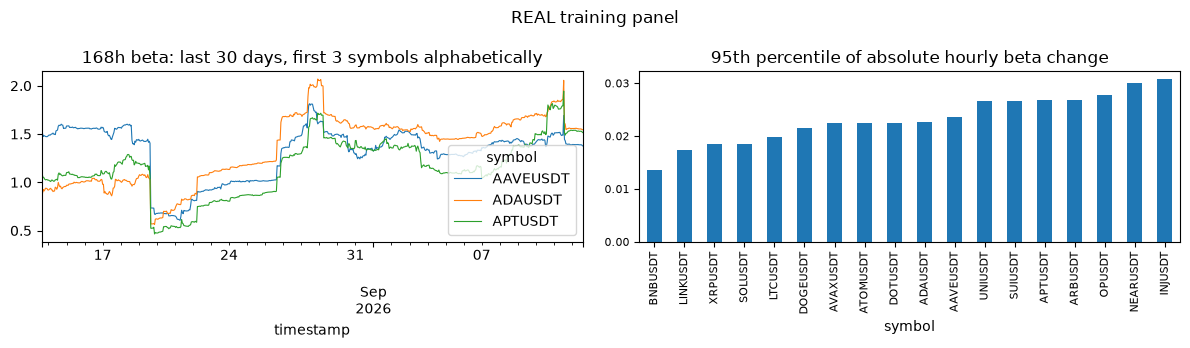

In [8]:
display(coins168.round(5))
display(variance168.round(6))
fig,axes=plt.subplots(1,2,figsize=(12,3.5))
names=sorted(F168['beta'].columns)[:3]  # fixed name order, no outcome-based selection
F168['beta'].loc[hourly168.index,names].tail(24*30).plot(ax=axes[0],lw=.8)
axes[0].set_title('168h beta: last 30 days, first 3 symbols alphabetically')
coins168['p95_abs_hourly_change'].sort_values().plot.bar(ax=axes[1],fontsize=8)
axes[1].set_title('95th percentile of absolute hourly beta change')
fig.suptitle(label);fig.tight_layout();plt.show()


## 6. Is beta materially changing the ranking?
The score is `-recent_alt_return + beta * recent_leader_return`. A correction that
is identical across all coins leaves their ranks unchanged. Different betas can
change ranks; the diagnostics quantify how much, not whether that change predicts.

`rank_agreement` is Spearman correlation between the catch-up and reversal scores
across 18 alts. Near 1 means nearly identical rankings; lower values mean more
reordering. Rank promotion is measured on 1..18, with **18 the strongest long score**.
No universal threshold separates a sensible ranking change from a bad one.


,n_hours,median_rank_agreement,p10_rank_agreement,median_mean_abs_rank_change,p95_max_abs_beta,median_abs_beta_change
group,,,,,,
all,14151,0.97110,0.82043,0.77778,2.08676,0.00260
strong,1455,0.95872,0.76883,1.00000,2.05548,0.00226
other,12696,0.97317,0.82869,0.77778,2.08931,0.00265


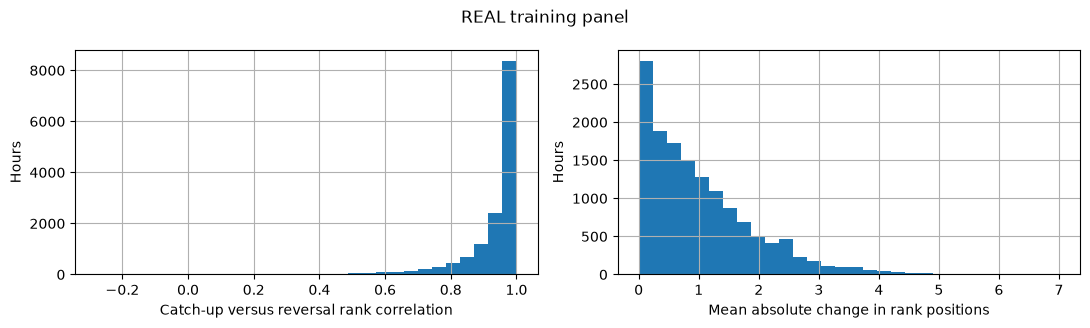

In [9]:
display(groups168.round(5))
fig,axes=plt.subplots(1,2,figsize=(11,3.3))
hourly168['rank_agreement'].hist(bins=30,ax=axes[0])
axes[0].set_xlabel('Catch-up versus reversal rank correlation');axes[0].set_ylabel('Hours')
hourly168['mean_abs_rank_change'].hist(bins=30,ax=axes[1])
axes[1].set_xlabel('Mean absolute change in rank positions');axes[1].set_ylabel('Hours')
fig.suptitle(label);fig.tight_layout();plt.show()


## 7. Concrete examples: what got promoted or demoted?
These are the three hours with the largest average ranking changes, selected only
from the inputs. They are deliberately extreme illustrations, not representative
performance evidence. Read them alongside the all-hour distribution above.

If recent leader returns are positive, larger positive betas add more to the score.
If leaders fell, larger positive betas subtract more. Check whether a large estimated
beta dominates the promotion. This is a diagnostic observation, not proof of error.


In [10]:
examples=ranking_examples(F168,hourly168,P)
with pd.option_context('display.max_rows',30,'display.max_columns',20):
    display(examples.round(6))


/var/folders/9k/92l6gffx0077ht3s2r0639kw0000gp/T/ipykernel_23613/2788970851.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(examples.round(6))


,timestamp,symbol,strong,beta,recent_alt_return,recent_leader_return,beta_term,reversal_signal,catchup_signal,reversal_rank,catchup_rank,rank_promotion
0,2026-06-04 01:00:00+00:00,NEARUSDT,False,2.145755,-0.077043,-0.054318,-0.116554,0.077043,-0.039510,16.0,1.0,-15.0
1,2026-06-04 01:00:00+00:00,APTUSDT,False,1.779867,-0.078584,-0.054318,-0.096679,0.078584,-0.018095,17.0,5.0,-12.0
2,2026-06-04 01:00:00+00:00,BNBUSDT,False,0.942006,-0.043932,-0.054318,-0.051168,0.043932,-0.007237,1.0,13.0,12.0
3,2026-06-04 01:00:00+00:00,LTCUSDT,False,0.879995,-0.055391,-0.054318,-0.047800,0.055391,0.007591,7.0,18.0,11.0
4,2026-06-04 01:00:00+00:00,ATOMUSDT,False,0.976391,-0.045031,-0.054318,-0.053036,0.045031,-0.008005,2.0,12.0,10.0
5,2026-06-04 01:00:00+00:00,OPUSDT,False,1.999890,-0.091162,-0.054318,-0.108631,0.091162,-0.017468,18.0,8.0,-10.0
6,2025-06-12 21:00:00+00:00,BNBUSDT,False,0.483824,-0.019744,-0.035853,-0.017346,0.019744,0.002398,1.0,15.0,14.0
7,2025-06-12 21:00:00+00:00,ARBUSDT,False,1.817136,-0.049825,-0.035853,-0.065149,0.049825,-0.015324,15.0,2.0,-13.0
8,2025-06-12 21:00:00+00:00,OPUSDT,False,1.977227,-0.066049,-0.035853,-0.070889,0.066049,-0.004840,18.0,6.0,-12.0
9,2025-06-12 21:00:00+00:00,XRPUSDT,False,0.742125,-0.027887,-0.035853,-0.026607,0.027887,0.001279,2.0,14.0,12.0


## 8. Decision before any new performance run
If betas barely move rankings, beta is unlikely to explain much incremental IC.
If rankings change substantially, that still need not be a problem: the previous
paired IC comparison tells you whether changes helped. Large input-driven jumps
or sensitivity during low leader variance motivate a longer-window diagnostic,
but do not prove that a longer window will improve predictions.

**Recommendation:** stop here if you do not see a defensible instability concern.
Record a negative result and proceed toward the assigned strategy/audit. If there
is a concern worth testing, paste the plan printed below in your PR, then enable
`RUN_336_COMPARISON=True` and restart/run all. No automatic GitHub posting occurs.


In [11]:
FOLLOWUP_PLAN="""Exploratory follow-up after the original and corrected real-panel results.
Question: does estimating beta over 336 rather than 168 hourly observations improve
the catch-up ranking? Hypothesis: extra history may reduce estimation noise, at
the cost of slower adaptation. No guaranteed improvement is assumed.
Only beta_window changes. Keep full windows, gap_window=4, impulse_span=4,
strong_quantile=.9, quantile_window=720, horizons=1/2/4/8/24 and lags=0/1.
Compare 168h beta, 336h beta and plain reversal on identical eligible hours/18 coins.
Focal comparison for presentation: lag 1, h=4; report every cell without selecting
the highest IC. Report joint 168-hour-block bootstrap pointwise 95% intervals,
1000 draws, seed 20261116, for 336-minus-168 and each versus reversal.
Also compare input stability and strong-minus-other IC. A smoother beta alone is
not success; a positive improvement over 168 does not establish superiority to
reversal or a profitable strategy. This is training research after seeing earlier
outcomes, not independent validation. Do not use holdout or forward data to tune.
Stop after this one variant; retain every result and do not silently extend the grid.
"""
print(FOLLOWUP_PLAN)


Exploratory follow-up after the original and corrected real-panel results.
Question: does estimating beta over 336 rather than 168 hourly observations improve
the catch-up ranking? Hypothesis: extra history may reduce estimation noise, at
the cost of slower adaptation. No guaranteed improvement is assumed.
Only beta_window changes. Keep full windows, gap_window=4, impulse_span=4,
strong_quantile=.9, quantile_window=720, horizons=1/2/4/8/24 and lags=0/1.
Compare 168h beta, 336h beta and plain reversal on identical eligible hours/18 coins.
Focal comparison for presentation: lag 1, h=4; report every cell without selecting
the highest IC. Report joint 168-hour-block bootstrap pointwise 95% intervals,
1000 draws, seed 20261116, for 336-minus-168 and each versus reversal.
Also compare input stability and strong-minus-other IC. A smoother beta alone is
not success; a positive improvement over 168 does not establish superiority to
reversal or a profitable strategy. This is training research af

## 9. Optional: build 336-hour beta and compare input stability
This section is skipped by default. The causal checks run again for the longer
window. Both diagnostic tables use the same eligible hours before comparison.


In [12]:
comparison=None
stability_comparison=None
F336=None
causality336=None
if RUN_336_COMPARISON:
    F336=build_features(df,P336)
    causality336=feature_causality_checks(df,P336)
    print(causality336)
    coins336,hourly336,groups336,variance336=beta_diagnostics(F336,P336)
    common=hourly168.index.intersection(hourly336.index)
    assert len(common)>0
    # Fixed 720h flow warm-up normally exceeds both beta windows; still enforce equality.
    a=F168['beta'].reindex(common);b=F336['beta'].reindex(common)
    da=F168['beta'].diff().abs().reindex(common)
    db=F336['beta'].diff().abs().reindex(common)
    stability_comparison=pd.DataFrame({
        'median_abs_change168':da.median(),'median_abs_change336':db.median(),
        'p95_abs_change168':da.quantile(.95),'p95_abs_change336':db.quantile(.95),
        'max_abs_beta168':a.abs().max(),'max_abs_beta336':b.abs().max()})
    display(stability_comparison.round(5))
    print('Lower changes mean smoother estimates, not automatically more accurate betas.')
else:
    print('Skipped. Review diagnostics and record the plan before enabling the new variant.')


Skipped. Review diagnostics and record the plan before enabling the new variant.


## 10. Optional: paired performance comparison
`delta336_minus168_strong` answers whether the longer beta helps relative to the
original during strong hours. `beta336_minus_reversal_strong` answers whether it
beats the simpler benchmark. `flow_difference336` tests the original strong-flow
conditioning question for the longer variant. These are distinct claims.

Intervals including zero mean insufficient evidence of a difference. The intervals
are pointwise, not a correction for ten comparisons or for this follow-up's selection.
Do not treat a single favorable cell as confirmation. Same-time paired resampling
preserves dependence between the signals and keeps missing rows on the hourly clock.


In [13]:
if RUN_336_COMPARISON:
    comparison,comparison_frames=compare_beta_windows(F168,F336,P,I)
    display(comparison[['ic168_strong','ic336_strong','ic_reversal_strong',
        'delta336_minus168_strong','delta_strong_low','delta_strong_high',
        'n_strong','n_other']].round(5))
    display(comparison[['beta336_minus_reversal_strong','beta336_vs_reversal_low',
        'beta336_vs_reversal_high','flow_difference336','beta336_flow_low','beta336_flow_high']].round(5))
    fig,axes=plt.subplots(1,len(P.lags),figsize=(6*len(P.lags),3.5),sharey=True)
    for ax,lag in zip(np.atleast_1d(axes),P.lags):
        part=comparison.loc[lag];x=np.array(part.index,dtype=float)
        ax.plot(x,part['delta336_minus168_strong'],'o-',color='C4')
        ax.fill_between(x,part['delta_strong_low'].to_numpy(dtype=float),
                        part['delta_strong_high'].to_numpy(dtype=float),color='C4',alpha=.15)
        ax.axhline(0,color='black',lw=.7)
        ax.set_xscale('log');ax.set_xticks(x);ax.set_xticklabels(P.horizons)
        ax.set_title(f'Lag {lag}: 336h minus 168h beta');ax.set_xlabel('Horizon (hours)')
    np.atleast_1d(axes)[0].set_ylabel('Difference in strong-hour mean IC')
    fig.suptitle(label+' — exploratory follow-up');fig.tight_layout();plt.show()
else:
    print('New performance experiment not run. Diagnostic-only outputs are still saved below.')


New performance experiment not run. Diagnostic-only outputs are still saved below.


## 11. Save the run and keep the original result
Each run uses a fresh directory. Diagnostic-only runs do not contain a new IC table.
The metadata records whether the optional comparison was enabled, the settings,
input/helper hashes and library versions. Record your reason for testing 336 hours
and link the posted plan when writing the PR; a local plan file alone is not proof
that it was posted before the run.


In [14]:
from datetime import datetime,timezone
from uuid import uuid4
import inspect
OUT=ROOT/'results'/('track03_beta_'+('real_' if USE_REAL_DATA else 'synthetic_')+
    datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+uuid4().hex[:6])
OUT.mkdir(parents=True,exist_ok=False)
coins168.to_csv(OUT/'beta168_by_coin.csv')
hourly168.to_csv(OUT/'beta168_hourly_diagnostics.csv')
groups168.to_csv(OUT/'beta168_group_diagnostics.csv')
variance168.to_csv(OUT/'low_variance_diagnostics.csv')
examples.to_csv(OUT/'ranking_examples.csv',index=False)
(OUT/'exploratory_plan.txt').write_text(FOLLOWUP_PLAN,encoding='utf-8')
if comparison is not None:
    comparison.to_csv(OUT/'beta_window_ic_comparison.csv')
    stability_comparison.to_csv(OUT/'beta_window_stability_comparison.csv')
    hourly_comparison=pd.concat([frame.assign(lag=lag,h=h)
        for (lag,h),(_,_,frame) in comparison_frames.items()])
    hourly_comparison.to_csv(OUT/'paired336_vs168_hourly_ic.csv',index_label='timestamp')
helper_path=Path(inspect.getfile(leader_flow_impulse))
metadata=dict(created_utc=datetime.now(timezone.utc).isoformat(),scope=label,
    baseline=asdict(P),followup=asdict(P336),inference=asdict(I),
    optional_comparison_executed=RUN_336_COMPARISON,
    data_sha256=hash_file(DATA_PATH) if USE_REAL_DATA else None,
    synthetic_seed=None if USE_REAL_DATA else 41,
    helper_sha256=hash_file(helper_path),causality168=causality168,causality336=causality336,
    python=platform.python_version(),pandas=pd.__version__,numpy=np.__version__,
    warning='Exploratory follow-up; no sealed validation, costs, trading weights or audit verdict.')
(OUT/'run_metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
print('Saved:',OUT)


Saved: /Users/janicejizhe/Desktop/quant sprint/open-quant-sprint/results/track03_beta_real_20261116T162957Z_261c40


## 12. What to do with the result
| Finding | Next action |
|---|---|
| Betas/ranks show no concerning instability | Keep the corrected result; no need to invent a new parameter search |
| 336h beta is smoother but IC improvement is inconclusive | Report that smoothing did not establish a predictive improvement |
| 336h beats 168h but not plain reversal | Better than the original does not establish incremental value over the benchmark |
| 336h clearly improves the planned comparison | Treat as exploratory evidence; disclose all cells and prior analysis |

After this bounded investigation, move toward the sprint deliverable rather than
repeatedly tuning: a causal dollar-neutral 18-alt strategy, documented holding
rule, turnover control, costs and the official audit output. Preserve the requested
beta-adjusted experiment even if you discuss reversal as a stronger benchmark.
Changing the track's submitted strategy to plain reversal needs agreement on scope.
The notebook does not submit a PR or choose a strategy for you.
